# Week 2: what the forecast means and how we measure it

## 1. Target, split and baseline note

**Proposed v1 target.** For a section that is **open now** (forecast origin *t0*) and a ticket time *T = t0 + h*:

> **P(section stays continuously open from t0 until T | open at t0)**

Label `y = 1` if every observation in (t0, T] is open and no observation gap could hide a closure; `y = 0` as soon as
one closed observation appears in (t0, T]. The forecast is made at several horizons *h* (e.g. 24 h, 72 h, 168 h).

**Not the same thing: "open at T" (after a possible reopening).** A section can close at hour 10 and reopen at hour 30,
so it is closed at some point yet open at T = 48. Target A (continuously open) says 0, target B (open at T) says 1.
Which one a student needs depends on the decision they are making. **Flag for Aaron and Arnav to settle before
labelling.** The notebook computes both so the gap can be sized (section 3).

**Hourly data rules (to agree with feature engineering).**
- Time is the hourly grid; an observation is `open` or `closed`. A failed or unknown fetch is **absent**, never `closed`.
- *Observation gap:* if consecutive observations are more than `max_gap_hours` apart (proposal: 3 h), an open-open pair
  does **not** prove continuity (it may have closed and reopened unseen). The row is **censored** and excluded from
  scoring, not labelled 1.
- A **closed** observation inside (t0, T] settles `y = 0` even across a gap.
- *Right censoring:* if the data ends before T, the row is censored (reason `end`).
- *Reopening:* a closed-then-open sequence gives `y = 0` for A, and is flagged `reopened = True`. Each reopening is also a
  new origin (open now) for later forecasts.
- Rows are always reported with their censoring rate per horizon, since censoring is not random (long horizons lose more).

**Evaluation.** Primary metric is the Brier score per horizon, with a reliability diagram (quantile bins, bin counts and 95% Wilson
intervals shown) and expected calibration error. Skill is reported against a reference forecast. Uncertainty comes from a
**section-level cluster bootstrap**, since the hourly rows of one section are highly correlated.

**Rolling time-based split.** Expanding window, ordered in time:
- Test origins fall in a window starting at `s`. Everything the model or baseline learns uses outcomes **known by `s`**:
  origin + horizon <= s. (Filtering on `resolved_at <= s` alone is wrong: early closures would be kept while still-pending
  successes are dropped, biasing training toward closure. Section 5 shows the size of that bias.)
- Any calibration adjustment is fit on the **validation window just before `s`** only, using predictions from a
  baseline fit even earlier, and then applied unchanged to the test window. The test window is never used for tuning.
- Several folds are run and the mean and spread are reported.

**Baseline: constant hazard.** One open-to-closed rate for the whole pool, estimated from training observations:
`rate = closures / open-hours-at-risk`, where only hour pairs observed within `max_gap_hours` count. The forecast is
`P(h) = exp(-rate * h)`, evaluated at the same horizons as any model. Limits: it ignores differences between
sections and the registration calendar, and it assumes memoryless closing. It is a floor to beat, not a claim about reality.
**Archived or frozen statuses show only the current state, not when it changed, so they are excluded from rate
estimation** (enforced in `trusted_only`).

**Status of evidence.** With a short pilot there are few closure events. Brier scores and reliability curves will be noisy and
cannot support a claim of calibrated forecasts. Until enough events exist per horizon, report them with intervals
and call them pilot diagnostics.

In [2]:
import sys
sys.path.insert(0, ".")  # so the notebook finds forecast_eval.py next to it
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from forecast_eval import *
pd.set_option("display.width", 140)

## 2. Label construction on hand-built cases

Five hand-written sections, observed hourly, origin at hour 0 (open), ticket at *h* = 12 h. `max_gap_hours = 3`.
Letters: `O` open, `C` closed, `.` no observation.

In [2]:
cases = {
    "A_steady_open":       "OOOOOOOOOOOOO",
    "B_closes_hour_5":     "OOOOOCCCCCCCC",
    "C_close_then_reopen": "OOOCCCCCCOOOO",   # target A = 0, target B = 1
    "D_gap_hides_status":  "OOO......OOOOO",  # open-open across a 6 h gap: could have closed and reopened
    "E_data_ends_early":   "OOOOOO",          # ticket at hour 12 is beyond the data
}
t0 = pd.Timestamp("2027-01-01", tz="UTC")
rows = []
for name, pat in cases.items():
    for i, ch in enumerate(pat):
        if ch != ".":
            rows.append((name, t0 + pd.Timedelta(hours=i), "open" if ch == "O" else "closed"))
tiny = pd.DataFrame(rows, columns=["section", "observed_at", "status"])
L = build_labels(to_panel(tiny), horizons=[12], max_gap_hours=3)
base = int((t0 - pd.Timestamp(0, tz="UTC")) / pd.Timedelta(hours=1))
L = L[L["origin"] == base]
L[["section", "y_cont", "resolved_at", "censor_reason", "y_open_at_ticket", "reopened"]].assign(
    resolved_at=lambda d: d["resolved_at"] - base)

,section,y_cont,resolved_at,censor_reason,y_open_at_ticket,reopened
0,A_steady_open,1.0,12.0,,1.0,False
13,B_closes_hour_5,0.0,5.0,,0.0,False
18,C_close_then_reopen,0.0,3.0,,1.0,True
25,D_gap_hides_status,NaN,NaN,gap,1.0,False
33,E_data_ends_early,NaN,NaN,end,NaN,False


Reading the table: A is 1. B is 0 (resolved when the closed observation appears). C shows the disagreement: continuously-open
is 0 but open-at-ticket is 1. D is censored for `gap` rather than guessed as 1. E is censored for `end`.

## 3. Toy data: how much do the two targets differ, and what does censoring cost?

In [3]:
# TOY simulation: hourly open/closed chains, section-level hazards, random outages in observation.
obs, true_lam = simulate_toy_status(n_sections=150, n_days=90, seed=1)
obs = trusted_only(obs, allow_demo=True)   # toy rows are flagged is_demo, so we opt in explicitly
panel = to_panel(obs)
HORIZONS = [24, 72, 168]
labels = build_labels(panel, HORIZONS, origin_step=6, max_gap_hours=3)

summ = labels.groupby("horizon").agg(
    rows=("y_cont", "size"),
    censored=("y_cont", lambda s: s.isna().mean()),
    P_stay_open_A=("y_cont", "mean"),
    P_open_at_ticket_B=("y_open_at_ticket", "mean"),
    reopened_share=("reopened", "mean"))
summ.round(3)

,rows,censored,P_stay_open_A,P_open_at_ticket_B,reopened_share
horizon,,,,,
24,47172,0.043,0.923,0.948,0.021
72,47172,0.116,0.782,0.911,0.102
168,47172,0.203,0.545,0.896,0.251


(TOY) The reopened share is the fraction of origins where A and B can disagree. It grows with the horizon, and so
does censoring. In real data these numbers are what the target decision should be based on.

## 4. Toy reliability chart

Three **toy** predictors scored against the same toy labels (one horizon, pooled rolling test windows):
- *toy oracle*: uses each section's true simulated hazard (calibrated by construction up to noise),
- *constant hazard baseline*: the proposed baseline, fit on earlier data only,
- *toy overconfident*: the oracle pushed toward 0 and 1, to show what miscalibration looks like.

7 folds; test origins from hour +720 to +1896 of the toy series


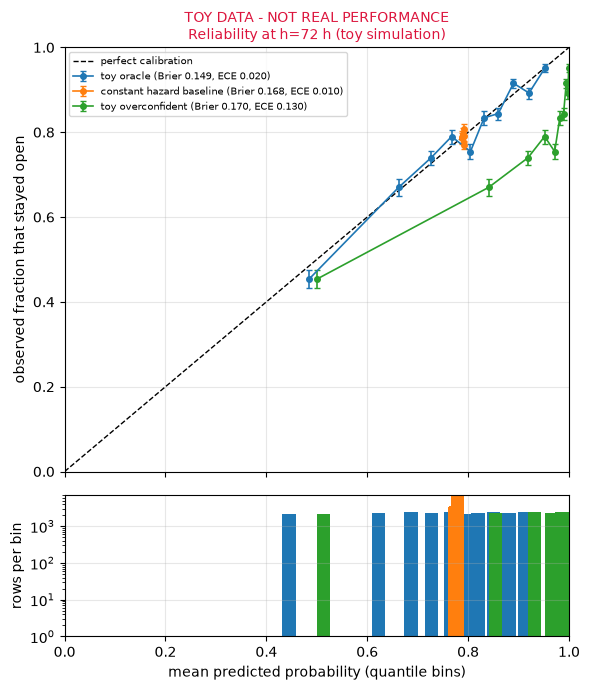

In [4]:
t0h = min(h[0] for h, _ in panel.values()); t_end = max(h[-1] for h, _ in panel.values())
folds = rolling_folds(first_test_start=t0h + 24 * 30, last_origin=t_end - max(HORIZONS),
                      test_window=24 * 7, val_window=24 * 14)
res = rolling_evaluation(panel, labels, folds, HORIZONS)
print(f"{len(folds)} folds; test origins from hour +{folds[0].test_range[0]-t0h} to +{folds[-1].test_range[1]-t0h} of the toy series")

h_show = 72
r = res[res["horizon"] == h_show].copy()
lam_i = r["section"].map(true_lam).to_numpy()
oracle = np.exp(-lam_i * h_show)
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
overconf = 1 / (1 + np.exp(-2.5 * logit(oracle)))
models = {"toy oracle": oracle, "constant hazard baseline": r["p_raw"].to_numpy(), "toy overconfident": overconf}

ax = plot_reliability(models, r["y_cont"], n_bins=10, strategy="quantile",
                      title=f"Reliability at h={h_show} h (toy simulation)", toy=True)
plt.savefig("week2_toy_reliability.png", dpi=150)
plt.show()

How to read it: points on the dashed diagonal are calibrated. The constant hazard baseline gives everyone the same probability,
so it collapses into a tight cluster (one value per fold): calibrated on average but with no sharpness. The oracle spreads out and stays near the
diagonal; the overconfident predictor sags well below the line (it says 90-100% when the observed rate is 70-90%). The bottom panel shows bin counts
(log scale) so thin bins are not over-read.

## 5. Rolling-origin evaluation of the constant-hazard baseline (toy)

Per horizon and over all folds: Brier score of the raw baseline, of the baseline after validation-fit Platt recalibration,
and of the reference "mean training label at this horizon". Intervals are section-cluster bootstrap 95%.

In [5]:
def summarize(g):
    lo, hi = bootstrap_ci(g["y_cont"], g["p_raw"], g["section"], n_boot=200)
    tab = reliability_table(g["y_cont"], g["p_raw"], 10)
    return pd.Series({
        "n": len(g), "observed_rate": g["y_cont"].mean(), "mean_forecast": g["p_raw"].mean(),
        "brier_raw": brier_score(g["y_cont"], g["p_raw"]), "brier_raw_lo": lo, "brier_raw_hi": hi,
        "brier_calibrated": brier_score(g["y_cont"], g["p_cal"]),
        "brier_train_rate": brier_score(g["y_cont"], g["p_train_rate"]),
        "skill_vs_train_rate": brier_skill_score(g["y_cont"], g["p_raw"], g["p_train_rate"]),
        "ece": expected_calibration_error(tab)})
pd.DataFrame({h: summarize(g) for h, g in res.groupby("horizon")}).T.round(4)

,n,observed_rate,mean_forecast,brier_raw,brier_raw_lo,brier_raw_hi,brier_calibrated,brier_train_rate,skill_vs_train_rate,ece
24,24840.0,0.9242,0.9246,0.0700,0.0617,0.0793,0.0701,0.0700,0.0000,0.0048
72,23344.0,0.7868,0.7905,0.1678,0.1539,0.1834,0.1680,0.1678,0.0000,0.0103
168,21620.0,0.5530,0.5777,0.2478,0.2416,0.2540,0.2472,0.2471,-0.0028,0.0336


In [6]:
# Spread across folds (mean and sd of per-fold Brier), as the note requires.
per_fold = pd.DataFrame({h: {k: brier_score(g["y_cont"], g["p_raw"]) for k, g in gh.groupby("fold")}
                         for h, gh in res.groupby("horizon")}).T
pd.DataFrame({"mean": per_fold.mean(axis=1), "sd": per_fold.std(axis=1)}).round(4)

,mean,sd
24,0.0701,0.0045
72,0.1678,0.0092
168,0.2477,0.0048


Notes on reading the above (toy): the baseline's Brier and the train-rate reference are very close because a single constant
hazard is essentially a base rate per horizon. Recalibration barely moves anything because the baseline is already
calibrated on average; it is fitted only if the validation window has at least 200 rows and 20 of each class, otherwise it stays identity.
A real model must beat both on Brier with an interval that excludes zero skill.

**Leakage check: why `origin + horizon <= cutoff`?** The wrong rule keeps rows with `resolved_at <= cutoff`:

In [7]:
cut = folds[1].train_cutoff
for h in HORIZONS:
    sub = labels[(labels["horizon"] == h) & labels["y_cont"].notna()]
    right = known_by(sub, cut)
    naive = sub[sub["resolved_at"] <= cut]
    print(f"h={h:>3}: correct train rate {right['y_cont'].mean():.3f} (n={len(right)})   "
          f"naive resolved_at rule {naive['y_cont'].mean():.3f} (n={len(naive)})")
assert_no_leakage(known_by(labels[labels["horizon"] == 72], cut), cut)
print("no-leakage assertion passed for the correct rule")

h= 24: correct train rate 0.922 (n=18434)   naive resolved_at rule 0.921 (n=18457)
h= 72: correct train rate 0.782 (n=16448)   naive resolved_at rule 0.774 (n=16607)
h=168: correct train rate 0.555 (n=13761)   naive resolved_at rule 0.530 (n=14420)
no-leakage assertion passed for the correct rule


The naive rule understates how often sections stay open (more so at long horizons, since successes resolve late and are
dropped), which would make forecasts too pessimistic. `known_by` and `assert_no_leakage` are used in the rolling driver for every fold.

## 6. For the meeting

**Decisions needed from Aaron and Arnav**
1. Target A (continuously open until the ticket) or B (open at the ticket, reopenings allowed), or both reported separately?
2. `max_gap_hours`: is 3 h right given the collector cadence? It sets what counts as censored.
3. Is a closed-then-open section a new origin for later forecasts (current proposal: yes)?
4. Which horizons matter to students (24 / 72 / 168 h are placeholders)?
5. What will the collector record when a fetch fails? It must be absent, not `closed`.

**Limits to state out loud**
- Numbers above are toy. Pilot data is not yet enough to claim calibrated forecasts.
- Archived or frozen statuses cannot establish past closure rates and are excluded.
- Constant hazard ignores section differences and the registration calendar; it is a baseline only.
- Calibration adjustment uses earlier validation data only; with few events it is skipped (identity).